# HuntFacts
## Sistem Temu Kembali Klarifikasi Hoaks Berbahasa Indonesia untuk Pesan Berantai Menggunakan TF-IDF dan BM25

**Mata kuliah:** Sistem Temu Kembali Informasi (STKI)
**Jenis proyek:** Information Retrieval murni (bukan klasifikasi hoaks dan bukan chatbot)

---

### Ide singkat
Pernah dapat kabar mengerikan di grup keluarga, lalu bingung ini sudah pernah dibantah atau belum? HuntFacts menerima **pesan atau klaim yang ditempel pengguna**, lalu mengembalikan **daftar artikel klarifikasi yang paling relevan** lengkap dengan skor, potongan teks yang kata kuncinya di-highlight, dan tautan ke artikel aslinya di turnbackhoax.id.

Sistem ini **tidak memvonis** pesan itu hoaks atau bukan. Tugasnya hanya menemukan klarifikasi yang terkait.

### Alur notebook
| Bagian | Isi |
|---|---|
| 0 | Setup |
| 1 | Pengumpulan dan audit data |
| 2 | Pembersihan data dan pembentukan koleksi dokumen |
| 3 | Preprocessing (termasuk komponen khusus pesan berantai) |
| 4 | Inverted index, TF-IDF, dan BM25 (plus validasi implementasi) |
| 5 | Mesin pencari dan tampilan hasil |
| 6 | Query uji, kunci jawaban, pooling, dan Cohen's kappa |
| 7 | Evaluasi (Precision@5, Recall@10, MRR, MAP) dan perbandingan skenario |
| 8 | Analisis query panjang, pemilihan kata kunci, dan analisis kegagalan |
| 9 | Menyimpan artefak dan menjalankan aplikasi Streamlit |
| 10 | Kesimpulan, batasan, dan rujukan |

### Hal penting sebelum menjalankan
1. Letakkan notebook ini sejajar dengan folder `data/` dan berkas `huntfacts_core.py`.
2. **Kunci jawaban pada folder `data/eval/` masih berupa draf awal.** Skor yang muncul dari draf itu hanya cocok untuk mengecek bahwa kode berjalan. Agar hasil evaluasimu sah, kamu perlu menulis ulang klaim ujinya dengan gayamu sendiri dan melakukan penilaian relevansi oleh dua orang (lihat bagian 6).
3. Run all membutuhkan sekitar 3 sampai 6 menit pada laptop biasa, terutama karena stemming Sastrawi.

## 0. Setup
Sel di bawah memasang library yang belum ada, lalu mengatur konfigurasi dasar. Kalau kamu memakai Google Colab, unggah folder proyek ini terlebih dahulu (atau unggah zip lalu `!unzip`).

In [2]:
import importlib
import subprocess
import sys


def ensure(pip_name, import_name):
    try:
        importlib.import_module(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])


for pip_name, import_name in [
    ("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
    ("PySastrawi", "Sastrawi"), ("rank_bm25", "rank_bm25"),
    ("scikit-learn", "sklearn"), ("scipy", "scipy"), ("matplotlib", "matplotlib"),
]:
    ensure(pip_name, import_name)

In [3]:
import json
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

import huntfacts_core as hf
from huntfacts_core import HuntFactsEngine, Preprocessor

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

SEED = 42
np.random.seed(SEED)

ROOT = Path(".")
DATA_XLSX = ROOT / "data" / "Meta Data.xlsx"
EVAL_DIR = ROOT / "data" / "eval"
ART_DIR = ROOT / "artifacts"
ART_DIR.mkdir(exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

print("Berkas data ada:", DATA_XLSX.exists())

Berkas data ada: True


## 1. Pengumpulan dan audit data

### 1.1 Sumber data
Data berasal dari repositori GitHub **JibranFawaid/turnbackhoax-dataset**. Isinya hasil scraping artikel dari portal pengecekan fakta **turnbackhoax.id** (dikelola komunitas MAFINDO). Salinan yang kamu unggah berisi:

- `Meta Data.xlsx`, berisi tiga sheet.
- `Scrapping.csv`, berformat titik koma dengan kolom `Label`, `Headline`, `Body`.
- Folder `code/`, berisi skrip PHP (Goutte) yang dipakai penulis dataset untuk scraping.

Untuk proyek retrieval ini, yang dibutuhkan adalah **judul, isi, dan tautan sumber**. Sel berikut mengecek tiap sheet supaya keputusan memilih sheet punya dasar yang jelas.

In [4]:
xls = pd.ExcelFile(DATA_XLSX)
audit = []
for sh in xls.sheet_names:
    d = xls.parse(sh)
    audit.append({"Sheet": sh, "Baris": len(d), "Kolom": ", ".join(map(str, d.columns)),
                  "Ada kolom Link": "Link" in d.columns})
display(pd.DataFrame(audit))

,Sheet,Baris,Kolom,Ada kolom Link
0,Hasil Scrapping,6975,"Header, Content, Link",True
1,Kategori,6975,"Kategori, Header, Content, Link",True
2,Fix,1116,"Label, Headline, Body",False


**Keputusan.** Sheet `Hasil Scrapping` dipakai karena satu-satunya yang memuat kolom `Header` (judul), `Content` (isi), **dan** `Link` (tautan ke artikel asli). Tautan ini wajib ada karena output sistem harus mengarahkan pengguna ke sumber aslinya. Sheet `Kategori` dan `Fix` tidak dipakai. `Fix` tidak punya tautan dan strukturnya memang disiapkan untuk klasifikasi, sedangkan proyek ini sengaja **tidak** diarahkan ke klasifikasi hoaks.

In [5]:
raw = pd.read_excel(DATA_XLSX, sheet_name="Hasil Scrapping")
raw.columns = [c.strip() for c in raw.columns]
print("Bentuk data mentah:", raw.shape)
display(raw.head(3))

Bentuk data mentah: (6975, 3)


,Header,Content,Link
0,"[FALSE] Inhaling Mothballs, Cloves, Carom Seeds, and Eucalyptus Oil Can Relieve Shortn...","There is no scientific evidence to suggest that inhaling camphor, cloves, or carom see...",https://turnbackhoax.id/2021/04/25/false-inhaling-mothballs-cloves-carom-seeds-and-euc...
1,[FALSE] Man Shot Dead at Masjidil Haram for Calling Anti-Government Slogans,The Makkah Police spokesman stated that the man was not shot dead for shouting anti-go...,https://turnbackhoax.id/2021/04/25/false-man-shot-dead-at-masjidil-haram-for-calling-a...
2,[SALAH] KRI Nanggala 402 Ditemukan Setelah 21 Jam Hilang Kontak,Hasil periksa fakta Aisyah Adilah (Anggota Komisariat MAFINDO Institut Ilmu Sosial Ilm...,https://turnbackhoax.id/2021/04/24/salah-kri-nanggala-402-ditemukan-setelah-21-jam-hil...


### 1.2 Audit kualitas data
Sebelum dibersihkan, kita ukur dulu masalahnya: data kosong, duplikat, panjang dokumen, dan kemungkinan teks terpotong. Catatan teknis: Excel membatasi isi satu sel maksimal 32.767 karakter, jadi artikel yang panjangnya persis segitu hampir pasti terpotong.

In [6]:
audit_rows = {
    "Total baris": len(raw),
    "Header kosong": int(raw["Header"].isna().sum()),
    "Content kosong": int(raw["Content"].isna().sum()),
    "Link kosong": int(raw["Link"].isna().sum()),
    "Link duplikat": int(raw["Link"].duplicated().sum()),
    "Header duplikat": int(raw["Header"].duplicated().sum()),
    "Content duplikat": int(raw["Content"].duplicated().sum()),
    "Content terpotong (tepat 32.767 karakter)": int((raw["Content"].astype(str).str.len() == 32767).sum()),
}
display(pd.Series(audit_rows, name="Jumlah").to_frame())

lens = raw["Content"].dropna().astype(str).str.split().str.len()
print("\nStatistik jumlah kata per artikel:")
display(lens.describe().round(1).to_frame("jumlah kata").T)

,Jumlah
Total baris,6975
Header kosong,1
Content kosong,1
Link kosong,0
Link duplikat,0
Header duplikat,13
Content duplikat,4
Content terpotong (tepat 32.767 karakter),6



Statistik jumlah kata per artikel:


,count,mean,std,min,25%,50%,75%,max
jumlah kata,6974.0,442.0,380.7,1.0,251.0,344.0,499.0,4597.0


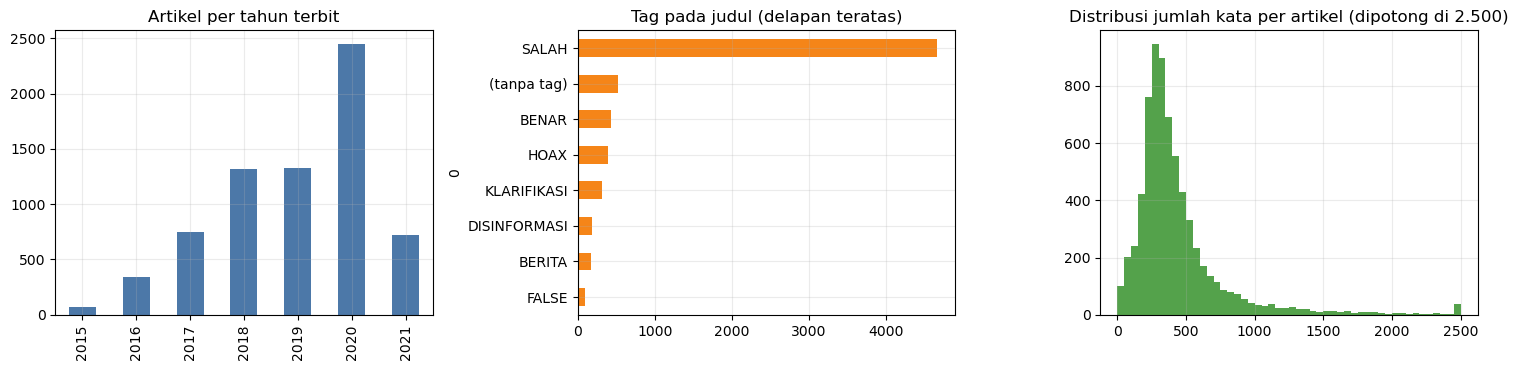

In [7]:
years = raw["Link"].str.extract(r"turnbackhoax\.id/(\d{4})/")[0].dropna().astype(int).value_counts().sort_index()
tags = raw["Header"].dropna().str.extract(r"^\s*\[([^\]]{1,25})\]")[0].str.upper().fillna("(tanpa tag)").value_counts().head(8)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
years.plot.bar(ax=ax[0], color="#4C78A8"); ax[0].set_title("Artikel per tahun terbit"); ax[0].set_xlabel("")
tags.plot.barh(ax=ax[1], color="#F58518"); ax[1].invert_yaxis(); ax[1].set_title("Tag pada judul (delapan teratas)")
ax[2].hist(lens.clip(upper=2500), bins=50, color="#54A24B"); ax[2].set_title("Distribusi jumlah kata per artikel (dipotong di 2.500)")
plt.tight_layout(); plt.show()

**Catatan dari audit:**
- Distribusi tahun menunjukkan **cakupan waktu koleksi**. Pesan berantai yang muncul setelah periode scraping tidak akan ditemukan klarifikasinya. Ini harus ditulis sebagai batasan.
- Tag pada judul (misalnya `[SALAH]`, `[HOAX]`) hanya **label dari situs sumber**. Tag ini dibuang dari judul yang diindeks supaya kata seperti "salah" tidak mengotori pencocokan, dan **tidak** ditampilkan sebagai vonis oleh sistem.
- Sebagian artikel berbahasa Inggris (misalnya yang bertag `[FALSE]`). Stemmer Sastrawi dirancang untuk bahasa Indonesia, jadi artikel ini cenderung kurang terwakili.

## 2. Pembersihan data dan pembentukan koleksi dokumen

Langkah pembersihan:
1. Buang baris yang judul, isi, atau tautannya kosong.
2. Buang duplikat berdasarkan tautan, lalu berdasarkan isi.
3. Pisahkan **tag** dari judul.
4. Pecah isi artikel menjadi bagian-bagiannya. Artikel turnbackhoax.id biasanya punya penanda seperti `====== KATEGORI`, `SUMBER`, `NARASI`, dan `PENJELASAN`.
5. Buat kolom `content_display` (teks rapi untuk ditampilkan) dan `doc_id` yang stabil.

Bagian **NARASI** adalah kutipan pesan hoaks aslinya. Bagian ini sengaja tetap ikut diindeks, karena pengguna biasanya menempelkan pesan yang kata-katanya mirip dengan narasi tersebut.

In [8]:
log = []
df = raw.copy()
log.append(("Data mentah", len(df)))

df = df.dropna(subset=["Header", "Content", "Link"])
log.append(("Setelah buang baris kosong", len(df)))

df = df.drop_duplicates(subset="Link")
log.append(("Setelah buang duplikat Link", len(df)))

df = df.drop_duplicates(subset="Content").reset_index(drop=True)
log.append(("Setelah buang duplikat Content", len(df)))

display(pd.DataFrame(log, columns=["Tahap", "Jumlah dokumen"]))

,Tahap,Jumlah dokumen
0,Data mentah,6975
1,Setelah buang baris kosong,6973
2,Setelah buang duplikat Link,6973
3,Setelah buang duplikat Content,6969


In [9]:
TAG_RE = re.compile(r"^\s*\[[^\]]{1,25}\]\s*:?\s*")
SEC_RE = re.compile(r"={3,}\s*\(?(KATEGORI|SUMBER|NARASI|PENJELASAN|REFERENSI|KESIMPULAN)\)?\s*:?")


def clean_title(h):
    return TAG_RE.sub("", str(h)).strip().strip('"\u201c\u201d').strip()


def split_sections(text):
    parts = SEC_RE.split(str(text))
    sec = {"RINGKASAN": parts[0].strip()}
    for i in range(1, len(parts) - 1, 2):
        sec[parts[i]] = parts[i + 1].strip()
    return sec


def make_display(text):
    t = SEC_RE.sub(lambda m: " | " + m.group(1).title() + ": ", str(text))
    t = hf.URL_RE.sub(" ", t)
    return re.sub(r"\s+", " ", t).strip()


df["doc_id"] = np.arange(len(df))
df["tag"] = df["Header"].str.extract(r"^\s*\[([^\]]{1,25})\]")[0].str.upper()
df["title"] = df["Header"].map(clean_title)
secs = df["Content"].map(split_sections)
df["narasi"] = secs.map(lambda s: s.get("NARASI", ""))
df["sumber"] = secs.map(lambda s: s.get("SUMBER", ""))
df["content_display"] = df["Content"].map(make_display)
df["link"] = df["Link"]
df["date"] = pd.to_datetime(df["Link"].str.extract(r"turnbackhoax\.id/(\d{4}/\d{2}/\d{2})/")[0], format="%Y/%m/%d", errors="coerce")
df["from_chain"] = df["sumber"].str.contains(r"whatsapp|pesan berantai", case=False, regex=True)
df["truncated"] = df["Content"].str.len() >= 32767

docs = df[["doc_id", "title", "tag", "content_display", "narasi", "sumber", "link", "date", "from_chain", "truncated"]].copy()
docs.to_csv(ART_DIR / "docs_clean.csv", index=False, encoding="utf-8")

print(f"Koleksi akhir: {len(docs):,} dokumen")
print(f"Rentang tanggal terbit: {docs['date'].min().date()} sampai {docs['date'].max().date()}")
print(f"Artikel yang sumbernya tercatat WhatsApp atau pesan berantai: {int(docs['from_chain'].sum()):,} ({docs['from_chain'].mean():.1%})")
print(f"Artikel yang kemungkinan terpotong: {int(docs['truncated'].sum())}")
display(docs.sample(3, random_state=SEED)[["doc_id", "title", "tag", "link"]])

Koleksi akhir: 6,969 dokumen
Rentang tanggal terbit: 2015-07-31 sampai 2021-04-25
Artikel yang sumbernya tercatat WhatsApp atau pesan berantai: 304 (4.4%)
Artikel yang kemungkinan terpotong: 6


,doc_id,title,tag,link
5992,5992,Triawan Munaf Jadi Korban Hoax,KLARIFIKASI,https://turnbackhoax.id/2017/11/09/klarifikasi-triawan-munaf-jadi-korban-hoax/
3473,3473,"Rangkap Jabatan Menteri Dan Anggota DPR, Puan: Khan Gajinya Dobel",SALAH,https://turnbackhoax.id/2019/10/05/salah-rangkap-jabatan-menteri-dan-anggota-dpr-puan-...
5107,5107,Menpora Halalkan Judi Bola,SALAH,https://turnbackhoax.id/2018/07/18/salah-menpora-halalkan-judi-bola/


## 3. Preprocessing

### 3.1 Tahapan
Tahapan yang dipakai, berurutan:

1. **Case folding** (huruf kecil semua).
2. **Hapus tautan, emoji, dan tanda baca** (termasuk kode emoji seperti `:birthday:` yang sering terbawa dari pesan WhatsApp).
3. **Tokenizing** per kata.
4. **Stopword removal** memakai daftar stopword Sastrawi plus enam penanda struktur artikel (`kategori`, `sumber`, `narasi`, `penjelasan`, `referensi`, `kesimpulan`) yang muncul di hampir semua dokumen tetapi tidak membawa isi klaim, ditambah (opsional) **stopword khusus pesan berantai**.
5. **Stemming** memakai PySastrawi.

### 3.2 Pembeda proyek ini: preprocessing khusus pesan berantai
Pesan berantai berbeda dari teks berita. Ada dua komponen tambahan yang diuji sebagai variabel eksperimen:

| Komponen | Isi | Alasan |
|---|---|---|
| **Stopword berantai** | `sebarkan`, `viralkan`, `share`, `mohon`, `tolong`, `assalamualaikum`, `grup`, dan sejenisnya | Kata ajakan menyebar tidak membawa informasi tentang isi klaim |
| **Normalisasi kata tidak baku** | `yg` menjadi `yang`, `gak` menjadi `tidak`, `udah` menjadi `sudah`, `teman2` menjadi `teman`, dan sejenisnya | Pesan WhatsApp informal, sedangkan artikel klarifikasi memakai bahasa baku |

Satu keputusan desain yang perlu dicatat: stopword berantai dicocokkan pada **kata mentah sebelum stemming**. Kalau dicocokkan setelah stemming, kata `sebar` ikut terbuang dan itu merusak query seperti "ISIS **menyebarkan** AIDS", karena `menyebarkan` dan `sebarkan` sama-sama distem menjadi `sebar`.

Dari dua komponen ini terbentuk empat konfigurasi pipeline yang akan dibandingkan.

In [10]:
PIPELINES = {
    "baseline": dict(chain_stop=False, slang_norm=False),
    "chain":    dict(chain_stop=True,  slang_norm=False),
    "slang":    dict(chain_stop=False, slang_norm=True),
    "full":     dict(chain_stop=True,  slang_norm=True),
}
PRE_NAMES = {
    "baseline": "Baseline (stopword standar)",
    "chain":    "+ Stopword pesan berantai",
    "slang":    "+ Normalisasi kata tidak baku",
    "full":     "Lengkap (keduanya)",
}
PRE = {name: Preprocessor(**cfg) for name, cfg in PIPELINES.items()}

print("Jumlah stopword dasar (Sastrawi + penanda struktur artikel):", len(hf.BASE_STOPWORDS))
print("Jumlah stopword khusus berantai  :", len(hf.CHAIN_STOPWORDS))
print("Jumlah entri normalisasi tidak baku:", len(hf.SLANG))

Jumlah stopword dasar (Sastrawi + penanda struktur artikel): 815
Jumlah stopword khusus berantai  : 87
Jumlah entri normalisasi tidak baku: 89


### 3.3 Demo tahap demi tahap
Contoh pesan berantai berikut dipakai untuk menunjukkan perubahan teks di setiap tahap. Hasil ini bisa langsung dijadikan tabel atau gambar di laporan.

In [11]:
contoh = ("Assalamualaikum, mohon ijin sharing ya. Heboh!! Minum air rebusan daun sirsak bisa sembuhin kanker dlm 3 hari. "
          "Tolong DISEBARKAN ke 10 grup \U0001F64F\U0001F64F https://bit.ly/xyz123 #viral")

for name in ["baseline", "full"]:
    print(f"=== Pipeline: {PRE_NAMES[name]} ===")
    for k, v in PRE[name].explain(contoh).items():
        print(f"{k:>18} : {v}")
    print()

=== Pipeline: Baseline (stopword standar) ===
            1_asli : Assalamualaikum, mohon ijin sharing ya. Heboh!! Minum air rebusan daun sirsak bisa sembuhin kanker dlm 3 hari. Tolong DISEBARKAN ke 10 grup 🙏🙏 https://bit.ly/xyz123 #viral
          2_bersih : assalamualaikum mohon ijin sharing ya heboh minum air rebusan daun sirsak bisa sembuhin kanker dlm 3 hari tolong disebarkan ke 10 grup viral
           3_token : ['assalamualaikum', 'mohon', 'ijin', 'sharing', 'ya', 'heboh', 'minum', 'air', 'rebusan', 'daun', 'sirsak', 'bisa', 'sembuhin', 'kanker', 'dlm', '3', 'hari', 'tolong', 'disebarkan', 'ke', '10', 'grup', 'viral']
  4_tanpa_stopword : ['assalamualaikum', 'ijin', 'sharing', 'heboh', 'minum', 'air', 'rebusan', 'daun', 'sirsak', 'sembuhin', 'kanker', 'dlm', 'tolong', 'disebarkan', '10', 'grup', 'viral']
            5_stem : ['assalamualaikum', 'ijin', 'sharing', 'heboh', 'minum', 'air', 'rebus', 'daun', 'sirsak', 'sembuhin', 'kanker', 'dlm', 'tolong', 'sebar', '10', 'grup', 'vi

### 3.4 Tokenisasi seluruh koleksi
Tahap pembersihan dan tokenizing dikerjakan **sekali saja** untuk semua dokumen. Tahap stopword dan stemming yang berbeda antar pipeline kemudian dijalankan di atas token tersebut. Stemming sendiri memakai cache per kata unik, jadi kata yang sama tidak dihitung ulang. Cache disimpan ke berkas supaya run berikutnya jauh lebih cepat.

In [12]:
CACHE_FILE = ART_DIR / "stem_cache.json"
if CACHE_FILE.exists():
    hf.STEM_CACHE.update(json.loads(CACHE_FILE.read_text(encoding="utf-8")))
    print("Cache stemming dimuat:", len(hf.STEM_CACHE), "kata")

t0 = time.time()
base_pre = PRE["baseline"]
RAW_TITLE = [base_pre.raw_tokens(x) for x in docs["title"]]
RAW_CONTENT = [base_pre.raw_tokens(x) for x in docs["content_display"]]
print(f"Tokenisasi selesai dalam {time.time() - t0:.1f} detik")
print(f"Total token isi (sebelum stopword): {sum(map(len, RAW_CONTENT)):,}")

Cache stemming dimuat: 90557 kata
Tokenisasi selesai dalam 3.5 detik
Total token isi (sebelum stopword): 3,075,223


## 4. Inverted index, TF-IDF, dan BM25

### 4.1 Struktur indeks
Inverted index menyimpan, untuk setiap term, daftar dokumen yang memuatnya beserta frekuensinya:

`term -> [(doc_id, tf), (doc_id, tf), ...]`

Indeks dibuat **dua field**, yaitu **judul** dan **isi**, lalu skor akhirnya digabung linear:

$$\text{skor}(q,d) = w_c \cdot s_{\text{isi}}(q,d) + w_t \cdot s_{\text{judul}}(q,d)$$

Bobot judul $w_t$ yang lebih besar berarti kecocokan di judul dianggap lebih penting. Nilai $w_t = 0$ sama dengan memakai isi saja.

### 4.2 TF-IDF dengan cosine similarity
$$w_{t,d} = (1+\ln tf_{t,d}) \cdot idf_t \qquad idf_t = \ln\frac{N+1}{df_t+1} + 1$$

$$\cos(q,d) = \frac{\sum_t w_{t,q}\, w_{t,d}}{\lVert q \rVert \, \lVert d \rVert}$$

### 4.3 BM25 (Okapi)
$$\text{BM25}(q,d) = \sum_{t \in q} idf_t \cdot \frac{tf_{t,d}\,(k_1+1)}{tf_{t,d} + k_1\left(1-b+b\,\frac{|d|}{avgdl}\right)} \qquad idf_t = \ln\left(1+\frac{N-df_t+0.5}{df_t+0.5}\right)$$

Parameter bawaan $k_1 = 1.5$ dan $b = 0.75$. Normalisasi panjang dokumen lewat $b$ relevan di sini karena panjang artikel klarifikasi sangat bervariasi (lihat histogram di bagian 1).

In [13]:
ENGINES = {}
for name in PIPELINES:
    t0 = time.time()
    ENGINES[name] = HuntFactsEngine.build(docs, PRE[name], RAW_TITLE, RAW_CONTENT)
    e = ENGINES[name]
    print(f"[{name:>8}] waktu bangun {time.time() - t0:5.1f} dtk | vocab isi {e.content.vocab_size:,} | "
          f"vocab judul {e.title.vocab_size:,} | rata-rata panjang dokumen {e.content.avgdl:,.0f} term")

CACHE_FILE.write_text(json.dumps(hf.STEM_CACHE), encoding="utf-8")

[baseline] waktu bangun   2.0 dtk | vocab isi 74,345 | vocab judul 9,303 | rata-rata panjang dokumen 271 term
[   chain] waktu bangun   2.0 dtk | vocab isi 74,303 | vocab judul 9,280 | rata-rata panjang dokumen 267 term
[   slang] waktu bangun   1.9 dtk | vocab isi 73,643 | vocab judul 9,221 | rata-rata panjang dokumen 269 term
[    full] waktu bangun   2.0 dtk | vocab isi 73,601 | vocab judul 9,198 | rata-rata panjang dokumen 265 term


2062891

### 4.4 Mengintip isi inverted index

In [14]:
E = ENGINES["full"]
term = hf.stem_word("kanker")
d_ids, tfs = E.content.post_docs[term], E.content.post_tf[term]
print(f"Term '{term}': muncul di {len(d_ids):,} dari {E.content.N:,} dokumen, idf BM25 = {E.content.idf_bm25[term]:.3f}")
print("Lima posting pertama (doc_id, tf):", list(zip(d_ids[:5].tolist(), tfs[:5].astype(int).tolist())))

top_df = pd.DataFrame(sorted(E.content.df.items(), key=lambda x: -x[1])[:12], columns=["term", "df"])
top_df["idf_bm25"] = top_df["term"].map(E.content.idf_bm25).round(3)
print("\nTerm dengan document frequency tertinggi (idf rendah, kurang membedakan dokumen):")
display(top_df.T)

Term 'kanker': muncul di 133 dari 6,969 dokumen, idf BM25 = 3.955
Lima posting pertama (doc_id, tf): [(32, 1), (41, 7), (70, 1), (107, 6), (122, 2)]

Term dengan document frequency tertinggi (idf rendah, kurang membedakan dokumen):


,0,1,2,3,4,5,6,7,8,9,10,11
term,akun,salah,com,konten,hasil,facebook,lengkap,media,edar,fakta,telusur,indonesia
df,4171,3938,3828,3807,3772,3745,3744,3498,3373,3252,3193,3118
idf_bm25,0.513,0.571,0.599,0.605,0.614,0.621,0.621,0.689,0.726,0.762,0.78,0.804


### 4.5 Validasi implementasi
Implementasi indeks ditulis sendiri, jadi perlu dibuktikan benar. Dua pengecekan:

1. **TF-IDF**: skor cosine dibandingkan dengan `TfidfVectorizer` milik scikit-learn (pengaturan setara). Selisihnya harus mendekati nol.
2. **BM25**: urutan teratas dibandingkan dengan library `rank_bm25`. Rumus idf kedua implementasi sedikit berbeda (milikku bergaya Lucene dan selalu positif), jadi yang dibandingkan adalah **irisan top-10**, bukan skor persisnya.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from rank_bm25 import BM25Okapi

E = ENGINES["full"]
docs_terms = [E.pre.terms_from_tokens(x) for x in RAW_CONTENT]

tv = TfidfVectorizer(sublinear_tf=True, token_pattern=r"\S+")
X = tv.fit_transform([" ".join(t) for t in docs_terms])
bm = BM25Okapi(docs_terms, k1=1.5, b=0.75)

tests = [
    "minum air rebusan daun sirsak bisa sembuhkan kanker",
    "listrik padam bergilir tiap 3 jam kata teman yang kerja di pln",
    "ada orang pura pura gila mau culik anak di depok",
]
rows = []
for q in tests:
    qt = E.query_terms(q)
    mine = E.content.score_tfidf(qt)
    sk = (X @ tv.transform([" ".join(qt)]).T).toarray().ravel()
    top_mine = set(np.argsort(-E.content.score_bm25(qt))[:10])
    top_rb = set(np.argsort(-bm.get_scores(list(set(qt))))[:10])
    rows.append({"query": q[:55], "selisih maks TF-IDF vs sklearn": f"{np.abs(mine - sk).max():.2e}",
                 "irisan top-10 BM25 vs rank_bm25": f"{len(top_mine & top_rb)}/10"})
display(pd.DataFrame(rows))

,query,selisih maks TF-IDF vs sklearn,irisan top-10 BM25 vs rank_bm25
0,minum air rebusan daun sirsak bisa sembuhkan kanker,5.55e-17,10/10
1,listrik padam bergilir tiap 3 jam kata teman yang kerja,1.11e-16,10/10
2,ada orang pura pura gila mau culik anak di depok,5.55e-17,10/10


## 5. Mesin pencari dan tampilan hasil

Fungsi `tampil` di bawah meniru antarmuka yang nanti dibuat di Streamlit: judul yang bisa diklik ke sumber asli, skor, dan potongan teks dengan kata kunci di-**highlight**. Highlight bekerja pada level kata asli, tetapi pencocokannya memakai hasil stemming, jadi "menyembuhkan" ikut ter-highlight kalau querynya memuat "sembuh".

Query contoh di bawah mengikuti skenario pada proposal proyek.

In [16]:
def tampil(query, engine=None, method="bm25", k=5, **kw):
    engine = engine or ENGINES["full"]
    qterms, rows = engine.search(query, method=method, top_k=k, **kw)
    out = [f"<p><b>Kata kunci setelah preprocessing:</b> {' '.join(qterms)}</p>"]
    for i, r in enumerate(rows, 1):
        out.append(
            '<div style="border:1px solid #bbb;border-radius:8px;padding:8px 12px;margin:6px 0">'
            f'<b>{i}. <a href="{r["link"]}" target="_blank">{r["title_html"]}</a></b> '
            f'<span style="color:#777">(skor {r["score"]:.3f})</span>'
            f'<div style="font-size:0.9em;margin-top:4px">{r["snippet_html"]}</div></div>'
        )
    display(HTML("".join(out)))
    return rows


q_demo = "Heboh! Minum air rebusan daun sirsak bisa sembuhkan kanker dlm 3 hari, tolong disebarkan ke 10 grup ya"
print("BM25")
_ = tampil(q_demo, method="bm25", k=4)
print("TF-IDF + Cosine")
_ = tampil(q_demo, method="tfidf", k=4)

BM25


TF-IDF + Cosine


Perhatikan bahwa skor BM25 dan skor cosine **tidak bisa dibandingkan langsung**. Cosine selalu berada di rentang 0 sampai 1, sedangkan skor BM25 tidak punya batas atas dan naik seiring banyaknya term query yang cocok. Perbandingan kedua metode dilakukan lewat metrik evaluasi, bukan lewat nilai skornya. Ini juga akan muncul lagi di bagian analisis query panjang.

## 6. Query uji, kunci jawaban, dan penilaian relevansi

### 6.1 Prinsip penyusunan query uji
Kualitas evaluasi bergantung pada kualitas query ujinya. Aturan yang dipakai:

- Jumlah 30 sampai 50 klaim. Berkas draf berisi 44 klaim.
- **Jangan menyalin judul artikel.** Judul dan isi artikel berbagi banyak kata, jadi query berupa judul akan menghasilkan skor yang tinggi tetapi tidak jujur.
- Tulis ulang sebagai **pesan berantai informal**: singkatan, huruf kecil semua, kadang typo, kadang ada ajakan menyebar.
- Tiap query punya satu **artikel sumber** (artikel yang memang membahas klaim itu). Artikel lain yang membahas klaim yang sama juga relevan, dan ini dicari lewat pooling di bagian 6.3.

### 6.2 Memuat query
Berkas `data/eval/queries_draft.csv` adalah **draf awal**. Supaya kunci jawabannya benar-benar buatanmu sendiri, baca dulu semua query itu, perbaiki dan tulis ulang dengan gayamu, tambahkan klaim baru dari artikel lain, lalu simpan hasilnya sebagai `data/eval/queries_final.csv` (format kolom sama). Notebook otomatis memakai `queries_final.csv` kalau berkasnya ada.

In [17]:
Q_FINAL, Q_DRAFT = EVAL_DIR / "queries_final.csv", EVAL_DIR / "queries_draft.csv"
Q_FILE = Q_FINAL if Q_FINAL.exists() else Q_DRAFT
print("Memakai berkas query:", Q_FILE.name, "(draf)" if Q_FILE == Q_DRAFT else "(final)")

queries = pd.read_csv(Q_FILE)
link2doc = dict(zip(docs["link"], docs["doc_id"]))
queries["source_doc"] = queries["source_link"].map(link2doc)
missing = queries[queries["source_doc"].isna()]
assert missing.empty, f"Link sumber tidak ditemukan di koleksi: {missing['query_id'].tolist()}"
queries["source_doc"] = queries["source_doc"].astype(int)

E = ENGINES["full"]


def title_overlap(q, title):
    a, b = set(E.pre.process(q)), set(E.pre.process(title))
    return len(a & b) / len(b) if b else 0.0


queries["n_kata"] = queries["query"].str.split().str.len()
queries["overlap_judul"] = [title_overlap(q, docs.loc[d, "title"]) for q, d in zip(queries["query"], queries["source_doc"])]

print(f"Jumlah query: {len(queries)}")
print(f"Rata-rata panjang query: {queries['n_kata'].mean():.1f} kata (min {queries['n_kata'].min()}, maks {queries['n_kata'].max()})")
print(f"Rata-rata overlap query dengan judul sumber: {queries['overlap_judul'].mean():.2f}")
print(f"Query yang memuat hampir semua kata judul (overlap >= 0.8): {(queries['overlap_judul'] >= 0.8).sum()}")
display(queries[["query_id", "query", "n_kata", "overlap_judul"]].head(8))

Memakai berkas query: queries_draft.csv (draf)
Jumlah query: 44
Rata-rata panjang query: 17.7 kata (min 12, maks 27)
Rata-rata overlap query dengan judul sumber: 0.65
Query yang memuat hampir semua kata judul (overlap >= 0.8): 13


,query_id,query,n_kata,overlap_judul
0,Q01,"info dr grup sebelah, lg dicari relawan nakes utk rawat pasien covid di wisma atlet ja...",27,0.375000
1,Q02,"kasian bgt, anak2 tk ditangkep polisi cuma gara2 latihan yel yel buat ikut demo. mahas...",18,0.857143
2,Q03,"pak tlg infokan ke temen2 taksi online, kalo jemput penumpang di sardjito pakai masker...",22,0.428571
3,Q04,waspada!! ada org ngaku dari fakultas kedokteran datang kerumah mau cek gula darah gra...,22,0.750000
4,Q05,"wah presiden pks syaikhu dipanggil kpk soal suap izin rs di cimahi, bakal nyusul presi...",17,0.750000
5,Q06,"pln lagi pasang alat deteksi gempa, kalo listrik mati terus lampu kedip 3x langsung ke...",26,1.000000
6,Q07,"jangan ke sendys dulu yaa, katanya ada klaster covid, 28 karyawannya positif sama pemi...",17,0.571429
7,Q08,"stop pacaran ayo nikah! nikah massal gratis di mall ciputra semarang, mahar sama rias ...",16,0.714286


Kolom `overlap_judul` menunjukkan berapa proporsi term judul sumber yang muncul lagi di query. Nilai mendekati 1 berarti query hampir menyalin judul. Angka ini bisa kamu laporkan sebagai bukti bahwa query ujimu tidak bias ke judul.

### 6.3 Pooling dan penilaian relevansi oleh dua orang
Menilai relevansi 6.969 artikel untuk setiap query jelas tidak mungkin. Praktik standar di IR adalah **pooling**: kumpulkan kandidat dari beberapa sistem, lalu nilai hanya kandidat itu. Di sini kandidatnya adalah gabungan top-10 dari empat sistem (TF-IDF dan BM25, masing-masing dengan preprocessing baseline dan lengkap) ditambah artikel sumbernya. Urutan baris diacak dan skor disembunyikan supaya penilai tidak terpengaruh peringkat sistem.

**Definisi relevan** yang disarankan: artikel membahas **klaim atau pesan yang sama** (atau versi lain dari klaim yang sama). Topik yang cuma mirip, misalnya sama-sama soal Covid, **tidak** dihitung relevan.

In [18]:
POOL_SYSTEMS = [("baseline", "tfidf"), ("baseline", "bm25"), ("full", "tfidf"), ("full", "bm25")]
POOL_DEPTH = 10

pool_rows = []
for _, q in queries.iterrows():
    cand = {int(q["source_doc"])}
    for pre_name, method in POOL_SYSTEMS:
        eng = ENGINES[pre_name]
        order, _ = eng.rank(eng.query_terms(q["query"]), method, POOL_DEPTH)
        cand.update(order.tolist())
    for d in cand:
        pool_rows.append({"query_id": q["query_id"], "query": q["query"], "doc_id": d,
                          "title": docs.loc[d, "title"], "link": docs.loc[d, "link"],
                          "ringkasan": docs.loc[d, "content_display"][:350], "relevan": ""})

pool = pd.DataFrame(pool_rows)
pool = pool.groupby("query_id", group_keys=False).sample(frac=1, random_state=SEED).sort_values("query_id", kind="stable")
pool.to_csv(EVAL_DIR / "pool_for_annotation.csv", index=False, encoding="utf-8-sig")

print(f"Pasangan (query, artikel) yang perlu dinilai: {len(pool)}  (rata-rata {len(pool) / len(queries):.1f} per query)")
print("Berkas dibuat: data/eval/pool_for_annotation.csv")

Pasangan (query, artikel) yang perlu dinilai: 678  (rata-rata 15.4 per query)
Berkas dibuat: data/eval/pool_for_annotation.csv


**Cara pakai berkas pool:**
1. Buka `pool_for_annotation.csv` di Excel atau Google Sheets.
2. Isi kolom `relevan` dengan **1** (relevan) atau **0** (tidak relevan) untuk setiap baris. Baca judul dan ringkasan, kalau ragu buka tautannya.
3. Simpan sebagai `data/eval/annotator_A.csv` (penilaian kamu, semua query).
4. Minta satu teman menilai **tanpa melihat jawabanmu**, minimal 10 sampai 15 query, lalu simpan sebagai `data/eval/annotator_B.csv` (format kolom sama, baris yang tidak dinilai boleh kosong).
5. Jalankan ulang sel-sel mulai dari bawah ini. Notebook otomatis menghitung Cohen's kappa dan membangun kunci jawaban finalnya.

**Aturan penggabungan:** pada baris yang dinilai dua orang, artikel dianggap relevan hanya jika **keduanya** memberi 1. Baris yang tidak sepakat dicatat di tabel perbedaan penilaian untuk dibahas, dan itu bahan bagus untuk bagian diskusi laporan.

Kalau berkas `annotator_A.csv` belum ada, notebook memakai **kunci jawaban sementara** (hanya artikel sumber yang dianggap relevan) supaya seluruh kode tetap bisa jalan.

In [19]:
from sklearn.metrics import cohen_kappa_score


def kappa_label(k):
    if k is None or np.isnan(k):
        return "tidak terdefinisi"
    for lim, name in [(0.0, "kurang dari kebetulan (poor)"), (0.20, "sangat rendah (slight)"), (0.40, "cukup (fair)"),
                      (0.60, "sedang (moderate)"), (0.80, "kuat (substantial)"), (1.01, "hampir sempurna (almost perfect)")]:
        if k < lim or (lim == 0.0 and k < 0):
            return name
    return "hampir sempurna (almost perfect)"


def build_qrels(queries, eval_dir):
    fa, fb = eval_dir / "annotator_A.csv", eval_dir / "annotator_B.csv"
    info = {"status": "SEMENTARA (hanya artikel sumber dianggap relevan)", "kappa": None,
            "agreement": None, "n_overlap": 0, "disagree": pd.DataFrame()}
    if not fa.exists():
        return {r.query_id: {int(r.source_doc)} for r in queries.itertuples()}, info

    A = pd.read_csv(fa)[["query_id", "doc_id", "relevan"]].dropna(subset=["relevan"])
    A = A.assign(relevan=A["relevan"].astype(int)).rename(columns={"relevan": "rA"})
    final = A.copy()
    final["rel"] = final["rA"]
    info["status"] = "FINAL (penilaian annotator A)"
    if fb.exists():
        B = pd.read_csv(fb)[["query_id", "doc_id", "relevan"]].dropna(subset=["relevan"])
        B = B.assign(relevan=B["relevan"].astype(int)).rename(columns={"relevan": "rB"})
        both = A.merge(B, on=["query_id", "doc_id"], how="inner")
        if len(both):
            info["n_overlap"] = len(both)
            info["agreement"] = float((both["rA"] == both["rB"]).mean())
            info["kappa"] = float(cohen_kappa_score(both["rA"], both["rB"]))
            info["disagree"] = both[both["rA"] != both["rB"]]
        final = A.merge(B, on=["query_id", "doc_id"], how="left")
        final["rel"] = np.where(final["rB"].isna(), final["rA"], ((final["rA"] == 1) & (final["rB"] == 1)).astype(int))
        info["status"] = "FINAL (dua annotator, relevan jika keduanya setuju)"
    qrels = {qid: set(g.loc[g["rel"] == 1, "doc_id"].astype(int)) for qid, g in final.groupby("query_id")}
    return qrels, info


QRELS, QINFO = build_qrels(queries, EVAL_DIR)
queries_eval = queries[queries["query_id"].map(lambda q: len(QRELS.get(q, ())) > 0)].reset_index(drop=True)

print("Status kunci jawaban :", QINFO["status"])
print("Query yang dievaluasi:", len(queries_eval), "dari", len(queries))
print("Rata-rata jumlah artikel relevan per query:", round(np.mean([len(QRELS[q]) for q in queries_eval["query_id"]]), 2))
if QINFO["kappa"] is not None:
    print(f"Baris yang dinilai dua orang : {QINFO['n_overlap']}")
    print(f"Persentase kesepakatan       : {QINFO['agreement']:.1%}")
    print(f"Cohen's kappa                : {QINFO['kappa']:.3f}  -> {kappa_label(QINFO['kappa'])}")
    if len(QINFO["disagree"]):
        display(QINFO["disagree"].merge(pool[["query_id", "doc_id", "title"]], on=["query_id", "doc_id"]).head(15))

Status kunci jawaban : SEMENTARA (hanya artikel sumber dianggap relevan)
Query yang dievaluasi: 44 dari 44
Rata-rata jumlah artikel relevan per query: 1.0


**Ilustrasi Cohen's kappa.** Sel di bawah memakai **data mainan** (bukan data penelitian) hanya untuk menunjukkan cara menghitungnya dan kenapa kappa lebih jujur daripada persentase kesepakatan biasa. Kalau dua penilai sama-sama banyak memberi 0, kesepakatan mentah bisa tinggi hanya karena kebetulan. Kappa mengoreksinya:

$$\kappa = \frac{p_o - p_e}{1 - p_e}$$

dengan $p_o$ kesepakatan yang teramati dan $p_e$ kesepakatan yang diharapkan karena kebetulan.

In [20]:
penilai_1 = [1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
penilai_2 = [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0]
po = np.mean(np.array(penilai_1) == np.array(penilai_2))
print(f"[DATA MAINAN] kesepakatan mentah = {po:.0%}, Cohen's kappa = {cohen_kappa_score(penilai_1, penilai_2):.3f}")

[DATA MAINAN] kesepakatan mentah = 90%, Cohen's kappa = 0.608


## 7. Evaluasi

### 7.1 Metrik
Misalkan untuk satu query, daftar hasil berperingkat adalah $d_1, d_2, \dots$ dan $R$ adalah himpunan artikel relevan.

| Metrik | Definisi | Kenapa dipakai |
|---|---|---|
| **Precision@5** | Proporsi artikel relevan di 5 teratas | Pengguna biasanya hanya melihat beberapa hasil pertama |
| **Recall@10** | Proporsi artikel relevan yang tertemu di 10 teratas | Seberapa lengkap klarifikasi terkait yang ditampilkan |
| **MRR** | Rata-rata $1/\text{peringkat}$ artikel relevan pertama | Cocok karena biasanya hanya ada sedikit jawaban benar |
| **MAP** | Rata-rata Average Precision, dihitung pada 100 peringkat teratas | Menilai kualitas seluruh urutan, bukan hanya posisi pertama |

Semua metrik dibuktikan dulu dengan unit test pada contoh kecil yang bisa dihitung manual.

In [21]:
def precision_at_k(ranked, rel, k):
    return sum(1 for d in ranked[:k] if d in rel) / k


def recall_at_k(ranked, rel, k):
    return sum(1 for d in ranked[:k] if d in rel) / len(rel)


def reciprocal_rank(ranked, rel):
    for i, d in enumerate(ranked, 1):
        if d in rel:
            return 1.0 / i
    return 0.0


def average_precision(ranked, rel):
    hits, total = 0, 0.0
    for i, d in enumerate(ranked, 1):
        if d in rel:
            hits += 1
            total += hits / i
    return total / len(rel)


# Unit test: relevan = {1, 2, 8}, urutan sistem = [5, 1, 9, 2, 7, 3]
toy, toy_rel = [5, 1, 9, 2, 7, 3], {1, 2, 8}
assert abs(precision_at_k(toy, toy_rel, 5) - 0.4) < 1e-9
assert abs(recall_at_k(toy, toy_rel, 10) - 2 / 3) < 1e-9
assert abs(reciprocal_rank(toy, toy_rel) - 0.5) < 1e-9
assert abs(average_precision(toy, toy_rel) - (1 / 2 + 2 / 4) / 3) < 1e-9
print("Semua unit test metrik lolos.")

Semua unit test metrik lolos.


In [22]:
METHOD_NAMES = {"tfidf": "TF-IDF + Cosine", "bm25": "BM25"}
DEPTH = 100


def run_system(engine, qdf, qrels, method="bm25", weights=(1.0, 0.0), reduce_k=None, k1=1.5, b=0.75):
    rows = []
    for q in qdf.itertuples():
        qt = engine.query_terms(q.query, reduce_k)
        order, sc = engine.rank(qt, method, DEPTH, weights=weights, k1=k1, b=b)
        ranked, rel = order.tolist(), qrels[q.query_id]
        first = next((i for i, d in enumerate(ranked, 1) if d in rel), np.nan)
        rows.append({"query_id": q.query_id, "n_qterms": len(set(qt)),
                     "P5": precision_at_k(ranked, rel, 5), "R10": recall_at_k(ranked, rel, 10),
                     "RR": reciprocal_rank(ranked, rel), "AP": average_precision(ranked, rel),
                     "rank_first": first, "top1_score": float(sc[0]) if len(sc) else 0.0})
    return pd.DataFrame(rows)


def summarize(res):
    return {"P@5": res["P5"].mean(), "R@10": res["R10"].mean(), "MRR": res["RR"].mean(), "MAP": res["AP"].mean()}


print("Query yang dievaluasi:", len(queries_eval), "| status kunci jawaban:", QINFO["status"])

Query yang dievaluasi: 44 | status kunci jawaban: SEMENTARA (hanya artikel sumber dianggap relevan)


**Catatan membaca Precision@5 dan Recall@10.** Kalau tiap query hanya punya **satu** artikel relevan, Precision@5 maksimalnya 0,2 (satu dari lima) dan Recall@10 sama dengan hit rate di 10 teratas. Angka ini baru informatif setelah pooling menemukan artikel relevan tambahan. Pada kondisi itu MRR dan MAP yang lebih berguna untuk membandingkan sistem.

### 7.2 Skenario utama: metode dan preprocessing
Delapan kombinasi (dua metode kali empat pipeline preprocessing), semuanya memakai isi artikel saja (bobot judul 0) dan parameter bawaan BM25.

,Preprocessing,Metode,P@5,R@10,MRR,MAP
0,Baseline (stopword standar),TF-IDF + Cosine,0.2,1.0,0.943,0.943
1,Baseline (stopword standar),BM25,0.2,1.0,0.945,0.945
2,+ Stopword pesan berantai,TF-IDF + Cosine,0.2,1.0,0.943,0.943
3,+ Stopword pesan berantai,BM25,0.2,1.0,0.945,0.945
4,+ Normalisasi kata tidak baku,TF-IDF + Cosine,0.2,1.0,0.955,0.955
5,+ Normalisasi kata tidak baku,BM25,0.2,1.0,0.949,0.949
6,Lengkap (keduanya),TF-IDF + Cosine,0.2,1.0,0.955,0.955
7,Lengkap (keduanya),BM25,0.2,1.0,0.938,0.938


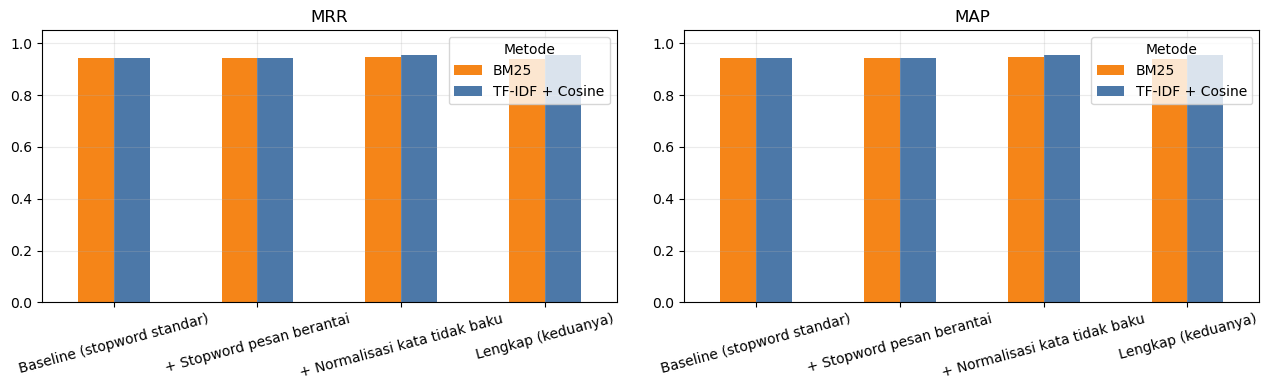

In [23]:
RESULTS, rows = {}, []
for pre_name in PIPELINES:
    for m in ["tfidf", "bm25"]:
        res = run_system(ENGINES[pre_name], queries_eval, QRELS, method=m)
        RESULTS[(pre_name, m)] = res
        rows.append({"Preprocessing": PRE_NAMES[pre_name], "Metode": METHOD_NAMES[m], **summarize(res)})

table_main = pd.DataFrame(rows)
display(table_main.round(3))

# grafik perbandingan
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["MRR", "MAP"]):
    piv = table_main.pivot(index="Preprocessing", columns="Metode", values=metric).loc[[PRE_NAMES[k] for k in PIPELINES]]
    piv.plot.bar(ax=ax, rot=15, color=["#F58518", "#4C78A8"])
    ax.set_title(metric); ax.set_xlabel(""); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

**Uji signifikansi.** Dengan puluhan query, selisih rata-rata yang kecil bisa saja hanya kebetulan. Karena skor per query tidak berdistribusi normal, dipakai uji peringkat bertanda Wilcoxon pada nilai Average Precision per query.

In [24]:
from scipy.stats import wilcoxon


def paired_test(res_a, res_b, col="AP"):
    a = res_a.set_index("query_id")[col]
    b = res_b.set_index("query_id").loc[a.index, col]
    diff = (b - a).values
    if np.allclose(diff, 0):
        return {"selisih rata-rata (B - A)": 0.0, "p-value": np.nan, "catatan": "tidak ada selisih"}
    stat, p = wilcoxon(a.values, b.values, zero_method="wilcox")
    return {"selisih rata-rata (B - A)": float(diff.mean()), "p-value": float(p), "catatan": ""}


tests = []
for pre_name in ["baseline", "full"]:
    tests.append({"Perbandingan": f"TF-IDF (A) vs BM25 (B), preprocessing {pre_name}",
                  **paired_test(RESULTS[(pre_name, "tfidf")], RESULTS[(pre_name, "bm25")])})
for m in ["tfidf", "bm25"]:
    tests.append({"Perbandingan": f"Baseline (A) vs Lengkap (B), metode {METHOD_NAMES[m]}",
                  **paired_test(RESULTS[("baseline", m)], RESULTS[("full", m)])})
display(pd.DataFrame(tests).round(4))
print("Baca: p-value di bawah 0,05 menandakan selisih konsisten antar query. Dengan jumlah query yang sedikit, uji ini punya daya terbatas.")

,Perbandingan,selisih rata-rata (B - A),p-value,catatan
0,"TF-IDF (A) vs BM25 (B), preprocessing baseline",0.0019,0.6803,
1,"TF-IDF (A) vs BM25 (B), preprocessing full",-0.0170,0.4142,
2,"Baseline (A) vs Lengkap (B), metode TF-IDF + Cosine",0.0114,0.3173,
3,"Baseline (A) vs Lengkap (B), metode BM25",-0.0076,0.6547,


Baca: p-value di bawah 0,05 menandakan selisih konsisten antar query. Dengan jumlah query yang sedikit, uji ini punya daya terbatas.


### 7.3 Pengaruh bobot judul
Pipeline terbaik dari tabel di atas dipakai untuk menguji bobot judul $w_t$. Nilai 0 berarti isi saja. Baris "judul saja" memakai indeks judul tanpa isi.

Pipeline dengan MAP rata-rata tertinggi: + Normalisasi kata tidak baku


MRR                    MAP                
Metode          BM25 TF-IDF + Cosine   BM25 TF-IDF + Cosine
Bobot                                                      
isi saja       0.949           0.955  0.949           0.955
w_judul = 0.5  0.945           0.946  0.945           0.946
w_judul = 1    0.947           0.930  0.947           0.930
w_judul = 2    0.945           0.917  0.945           0.917
w_judul = 3    0.934           0.906  0.934           0.906
judul saja     0.887           0.845  0.887           0.845

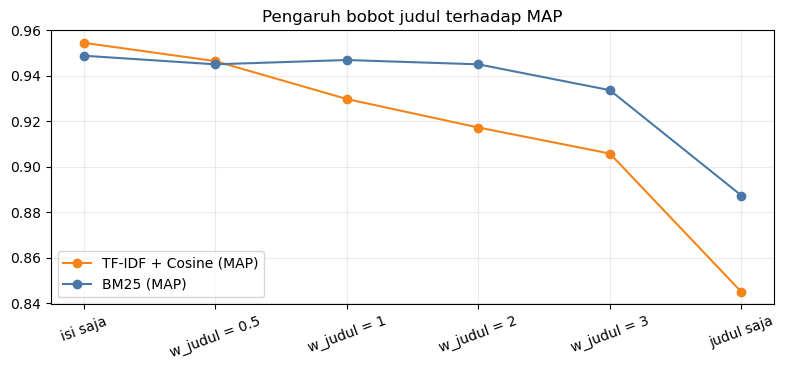

In [25]:
avg_map = table_main.groupby("Preprocessing")["MAP"].mean()
BEST_PRE = [k for k, v in PRE_NAMES.items() if v == avg_map.idxmax()][0]
print("Pipeline dengan MAP rata-rata tertinggi:", PRE_NAMES[BEST_PRE])

W_LIST = [("isi saja", (1.0, 0.0)), ("w_judul = 0.5", (1.0, 0.5)), ("w_judul = 1", (1.0, 1.0)),
          ("w_judul = 2", (1.0, 2.0)), ("w_judul = 3", (1.0, 3.0)), ("judul saja", (0.0, 1.0))]
rows = []
for label, w in W_LIST:
    for m in ["tfidf", "bm25"]:
        res = run_system(ENGINES[BEST_PRE], queries_eval, QRELS, method=m, weights=w)
        RESULTS[("w", label, m)] = res
        rows.append({"Bobot": label, "Metode": METHOD_NAMES[m], **summarize(res)})
table_w = pd.DataFrame(rows)
display(table_w.pivot(index="Bobot", columns="Metode", values=["MRR", "MAP"]).loc[[l for l, _ in W_LIST]].round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
for m, c in [("tfidf", "#F58518"), ("bm25", "#4C78A8")]:
    sub = table_w[table_w["Metode"] == METHOD_NAMES[m]].set_index("Bobot").loc[[l for l, _ in W_LIST]]
    ax.plot(sub.index, sub["MAP"], marker="o", label=f"{METHOD_NAMES[m]} (MAP)", color=c)
ax.set_title("Pengaruh bobot judul terhadap MAP"); ax.tick_params(axis="x", rotation=20); ax.legend()
plt.tight_layout(); plt.show()

### 7.4 Sensitivitas parameter BM25
Parameter $k_1$ mengatur seberapa cepat kontribusi frekuensi term jenuh, dan $b$ mengatur kuatnya normalisasi panjang dokumen. Grid kecil berikut hanya untuk melihat apakah hasil sensitif terhadap parameter.

**Peringatan metodologi:** kalau kamu memilih parameter terbaik dari grid ini lalu melaporkan skornya pada query yang sama, hasilnya sedikit terlalu optimis (tuning pada data uji). Laporkan skor dengan parameter bawaan ($k_1=1.5$, $b=0.75$) sebagai hasil utama dan perlakukan grid ini sebagai analisis tambahan.

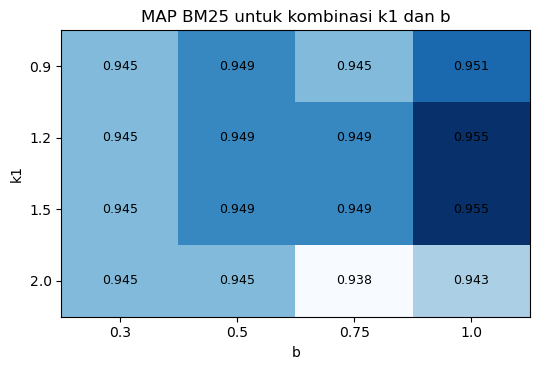

In [26]:
K1_LIST, B_LIST = [0.9, 1.2, 1.5, 2.0], [0.3, 0.5, 0.75, 1.0]
grid = np.zeros((len(K1_LIST), len(B_LIST)))
for i, k1 in enumerate(K1_LIST):
    for j, b in enumerate(B_LIST):
        grid[i, j] = run_system(ENGINES[BEST_PRE], queries_eval, QRELS, "bm25", k1=k1, b=b)["AP"].mean()

fig, ax = plt.subplots(figsize=(5.5, 3.8))
im = ax.imshow(grid, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(B_LIST))); ax.set_xticklabels(B_LIST); ax.set_xlabel("b")
ax.set_yticks(range(len(K1_LIST))); ax.set_yticklabels(K1_LIST); ax.set_ylabel("k1")
for i in range(len(K1_LIST)):
    for j in range(len(B_LIST)):
        ax.text(j, i, f"{grid[i, j]:.3f}", ha="center", va="center", color="black", fontsize=9)
ax.set_title("MAP BM25 untuk kombinasi k1 dan b"); ax.grid(False)
plt.tight_layout(); plt.show()

## 8. Analisis: kenapa pesan berantai yang panjang itu sulit

Pesan berantai itu panjang, informal, dan penuh kata yang tidak ada di artikel klarifikasi (sapaan, ajakan menyebar, doa). Ada dua efek yang perlu dipahami:

1. **Pada TF-IDF cosine**, setiap kata query ikut membentuk panjang vektor query. Kata-kata pengganggu yang tidak ada di dokumen menambah panjang vektor itu, sehingga nilai cosine dokumen yang benar ikut turun.
2. **Pada BM25**, skor adalah jumlah kontribusi tiap term query. Kata pengganggu yang tetap muncul di banyak dokumen (misalnya "Allah", "keluarga", "waspada") menambah skor dokumen yang tidak relevan, sehingga dokumen yang kebetulan banyak memuat kata umum bisa menyalip dokumen yang benar.

### 8.1 Hubungan panjang query dengan skor dan kualitas hasil

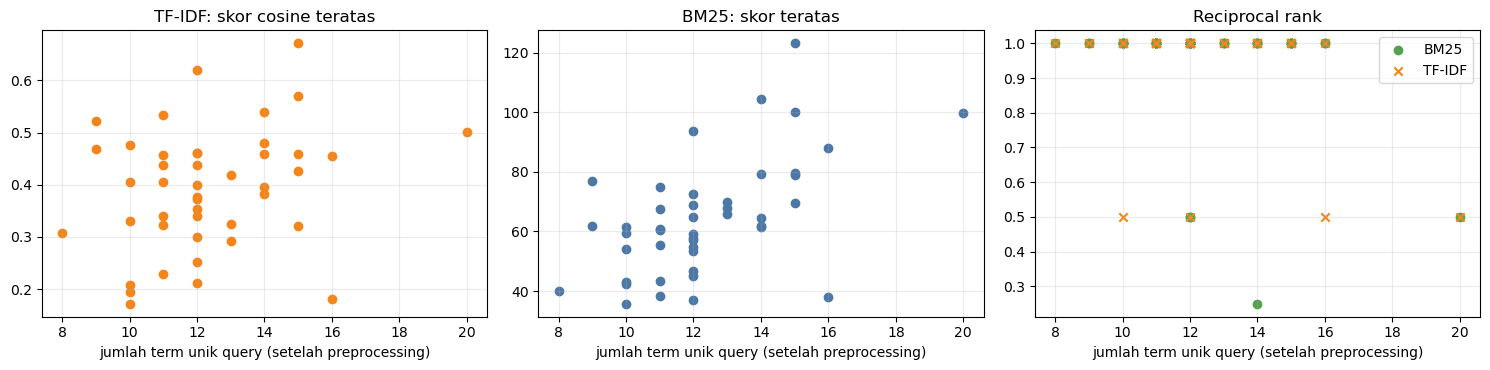

Korelasi Spearman jumlah term vs TF-IDF skor teratas     : rho = +0.23 (p = 0.140)
Korelasi Spearman jumlah term vs BM25 skor teratas       : rho = +0.54 (p = 0.000)
Korelasi Spearman jumlah term vs TF-IDF reciprocal rank  : rho = -0.16 (p = 0.296)
Korelasi Spearman jumlah term vs BM25 reciprocal rank    : rho = -0.21 (p = 0.171)


In [27]:
from scipy.stats import spearmanr

r_t = RESULTS[(BEST_PRE, "tfidf")]
r_b = RESULTS[(BEST_PRE, "bm25")]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].scatter(r_t["n_qterms"], r_t["top1_score"], color="#F58518"); ax[0].set_title("TF-IDF: skor cosine teratas")
ax[1].scatter(r_b["n_qterms"], r_b["top1_score"], color="#4C78A8"); ax[1].set_title("BM25: skor teratas")
ax[2].scatter(r_b["n_qterms"], r_b["RR"], color="#54A24B", label="BM25")
ax[2].scatter(r_t["n_qterms"], r_t["RR"], color="#F58518", marker="x", label="TF-IDF"); ax[2].set_title("Reciprocal rank"); ax[2].legend()
for a in ax:
    a.set_xlabel("jumlah term unik query (setelah preprocessing)")
plt.tight_layout(); plt.show()

for name, r, col in [("TF-IDF skor teratas", r_t, "top1_score"), ("BM25 skor teratas", r_b, "top1_score"),
                     ("TF-IDF reciprocal rank", r_t, "RR"), ("BM25 reciprocal rank", r_b, "RR")]:
    rho, p = spearmanr(r["n_qterms"], r[col])
    print(f"Korelasi Spearman jumlah term vs {name:<24}: rho = {rho:+.2f} (p = {p:.3f})")

Baca grafik ini dengan hati-hati. Skor BM25 yang naik bersama jumlah term **bukan** tanda hasilnya makin bagus, karena BM25 memang menjumlahkan kontribusi term. Yang penting dilihat adalah panel ketiga (kualitas peringkat) dan tabel kelompok panjang berikut.

In [28]:
def bucket_table(r_by_method):
    out = []
    base = r_by_method["bm25"].copy()
    base["kelompok"] = pd.qcut(base["n_qterms"], 3, labels=["pendek", "sedang", "panjang"], duplicates="drop")
    for m, r in r_by_method.items():
        tmp = r.merge(base[["query_id", "kelompok"]], on="query_id")
        g = tmp.groupby("kelompok", observed=True).agg(n_query=("RR", "size"), rata_rata_term=("n_qterms", "mean"),
                                                       MRR=("RR", "mean"), MAP=("AP", "mean"))
        g.insert(0, "Metode", METHOD_NAMES[m])
        out.append(g)
    return pd.concat(out)


display(bucket_table({"tfidf": r_t, "bm25": r_b}).round(3))

,Metode,n_query,rata_rata_term,MRR,MAP
kelompok,,,,,
pendek,TF-IDF + Cosine,16,10.188,0.969,0.969
sedang,TF-IDF + Cosine,15,12.200,0.967,0.967
panjang,TF-IDF + Cosine,13,15.154,0.923,0.923
pendek,BM25,16,10.188,1.000,1.000
sedang,BM25,15,12.200,0.933,0.933
panjang,BM25,13,15.154,0.904,0.904


### 8.2 Memilih kata kunci penting dari query panjang
Ide perbaikannya: sebelum mencari, ambil hanya $k$ term dengan **bobot IDF tertinggi** dari pesan. Term yang jarang muncul di koleksi (nama orang, tempat, angka khusus, istilah aneh) biasanya paling membedakan klaim, sedangkan kata umum punya IDF rendah dan otomatis tersingkir. Metode ini tidak memakai model bahasa apa pun, jadi tetap murni temu kembali.

MRR                    MAP                
Metode         BM25 TF-IDF + Cosine   BM25 TF-IDF + Cosine
k kata kunci                                              
3             0.715           0.679  0.715           0.679
5             0.898           0.879  0.898           0.879
8             0.926           0.940  0.926           0.940
10            0.936           0.962  0.936           0.962
15            0.949           0.966  0.949           0.966
20            0.949           0.966  0.949           0.966
semua         0.949           0.955  0.949           0.955

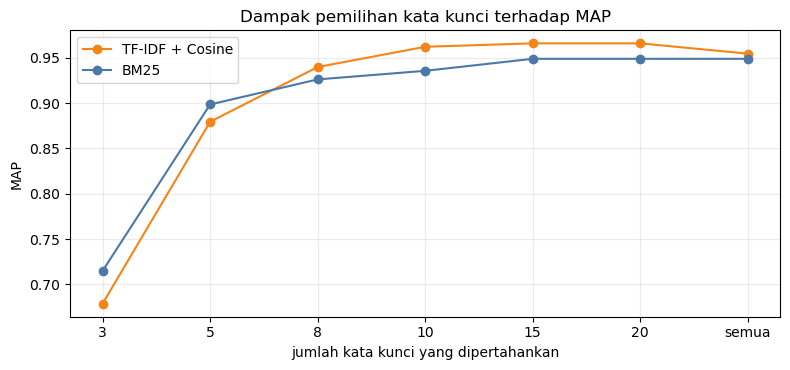

In [29]:
K_LIST = [3, 5, 8, 10, 15, 20, None]
rows = []
for m in ["tfidf", "bm25"]:
    for k in K_LIST:
        res = run_system(ENGINES[BEST_PRE], queries_eval, QRELS, m, reduce_k=k)
        rows.append({"Metode": METHOD_NAMES[m], "k kata kunci": "semua" if k is None else k, **summarize(res)})
table_k = pd.DataFrame(rows)
display(table_k.pivot(index="k kata kunci", columns="Metode", values=["MRR", "MAP"]).loc[[3, 5, 8, 10, 15, 20, "semua"]].round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
for m, c in [("tfidf", "#F58518"), ("bm25", "#4C78A8")]:
    sub = table_k[table_k["Metode"] == METHOD_NAMES[m]].set_index("k kata kunci").loc[[3, 5, 8, 10, 15, 20, "semua"]]
    ax.plot([str(i) for i in sub.index], sub["MAP"], marker="o", label=METHOD_NAMES[m], color=c)
ax.set_xlabel("jumlah kata kunci yang dipertahankan"); ax.set_ylabel("MAP"); ax.set_title("Dampak pemilihan kata kunci terhadap MAP"); ax.legend()
plt.tight_layout(); plt.show()

### 8.3 Uji ketahanan: pesan yang dipanjangkan dengan basa-basi
Query draf relatif pendek (rata-rata sekitar 18 kata). Pesan berantai asli sering jauh lebih panjang karena ada pembuka, doa, dan ajakan menyebar. Untuk mensimulasikannya, paragraf basa-basi standar ditempel ke setiap query sebanyak 0, 1, 2, atau 4 kali, lalu kualitas hasil dibandingkan antara pipeline baseline, pipeline lengkap, dan pipeline lengkap dengan pemilihan 10 kata kunci. Kunci jawabannya sama saja, karena isi klaimnya tidak berubah.

,MRR (+0 paragraf),MRR (+1 paragraf),MRR (+2 paragraf),MRR (+4 paragraf)
Konfigurasi,,,,
BM25 | Baseline (stopword standar),0.945,0.949,0.949,0.949
BM25 | Lengkap (keduanya),0.938,0.949,0.949,0.949
BM25 | Lengkap (keduanya) | 10 kata kunci,0.939,0.919,0.919,0.919
TF-IDF + Cosine | Baseline (stopword standar),0.943,0.939,0.852,0.739
TF-IDF + Cosine | Lengkap (keduanya),0.955,0.951,0.936,0.880
TF-IDF + Cosine | Lengkap (keduanya) | 10 kata kunci,0.962,0.934,0.934,0.934


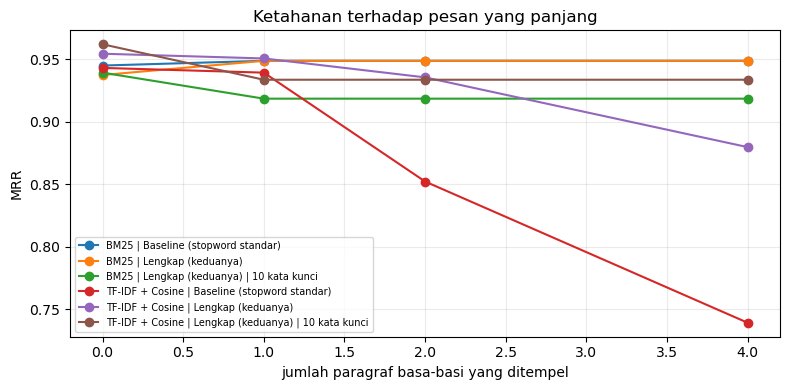

In [30]:
NOISE = ("Assalamualaikum bapak ibu, mohon maaf mengganggu waktunya. Tolong sebarkan pesan ini ke semua grup keluarga dan teman. "
         "Viralkan sebelum terlambat, jangan lupa share ya. Semoga bermanfaat dan Allah membalas kebaikan kita semua. Aamiin.")

configs = [("baseline", "bm25", None), ("full", "bm25", None), ("full", "bm25", 10),
           ("baseline", "tfidf", None), ("full", "tfidf", None), ("full", "tfidf", 10)]
rows = []
for pre_name, m, k in configs:
    label = f"{METHOD_NAMES[m]} | {PRE_NAMES[pre_name]}" + (f" | {k} kata kunci" if k else "")
    row = {"Konfigurasi": label}
    for n in [0, 1, 2, 4]:
        q_noise = queries_eval.assign(query=queries_eval["query"] + (" " + NOISE) * n)
        row[f"MRR (+{n} paragraf)"] = run_system(ENGINES[pre_name], q_noise, QRELS, m, reduce_k=k)["RR"].mean()
    rows.append(row)
stress = pd.DataFrame(rows).set_index("Konfigurasi")
display(stress.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for label, r in stress.iterrows():
    ax.plot([0, 1, 2, 4], r.values, marker="o", label=label)
ax.set_xlabel("jumlah paragraf basa-basi yang ditempel"); ax.set_ylabel("MRR"); ax.set_title("Ketahanan terhadap pesan yang panjang")
ax.legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()

**Catatan implementasi.** BM25 pada sistem ini memakai term query yang **unik**, jadi paragraf basa-basi yang sama ditempel berkali-kali tidak menambah term baru. Itu sebabnya kurva BM25 mendatar setelah paragraf pertama. TF-IDF cosine tidak begitu, karena frekuensi term query ikut menentukan bobot dan panjang vektor query. Kalau nanti kamu ingin menguji pesan berantai yang basa-basinya beragam (bukan paragraf yang sama diulang), hasil BM25 bisa berbeda.

### 8.4 Analisis kegagalan
Bagian ini sering mengangkat nilai laporan, karena menunjukkan kamu memahami **kenapa** sistemnya gagal. Sel di bawah mengambil query dengan peringkat terburuk pada konfigurasi terbaik, lalu menampilkan bukti otomatis: peringkat artikel sumbernya, kata-kata query yang **tidak ada** di artikel sumber (ketidakcocokan kosakata), dan artikel yang justru menempati peringkat satu.

Satu catatan penting. Kalau kunci jawabanmu masih sementara (hanya artikel sumber), artikel peringkat satu yang sebenarnya membahas klaim yang sama akan dihitung salah. Kolom `mirip_sumber` menandai kasus seperti itu. Setelah pooling dan penilaian manusia selesai, kasus ini akan berkurang dengan sendirinya.

In [31]:
best_row = table_main.sort_values("MAP", ascending=False).iloc[0]
BEST_METHOD = [k for k, v in METHOD_NAMES.items() if v == best_row["Metode"]][0]
BEST_PRE_MAIN = [k for k, v in PRE_NAMES.items() if v == best_row["Preprocessing"]][0]
print(f"Konfigurasi terbaik (MAP): {best_row['Metode']} dengan preprocessing '{best_row['Preprocessing']}'")

eng = ENGINES[BEST_PRE_MAIN]
res_best = RESULTS[(BEST_PRE_MAIN, BEST_METHOD)]
qmap = queries_eval.set_index("query_id")


def diagnose(qid):
    q = qmap.loc[qid]
    qt = set(eng.query_terms(q["query"]))
    src = int(q["source_doc"])
    src_terms = set(eng.pre.process(docs.loc[src, "content_display"])) | set(eng.pre.process(docs.loc[src, "title"]))
    order, _ = eng.rank(eng.query_terms(q["query"]), BEST_METHOD, DEPTH)
    top1 = int(order[0]) if len(order) else None
    sim = np.nan
    if top1 is not None:
        a, b = set(eng.pre.process(docs.loc[src, "title"])), set(eng.pre.process(docs.loc[top1, "title"]))
        sim = len(a & b) / len(a | b) if (a | b) else 0
    return {"query_id": qid, "query": q["query"][:70] + "...", "peringkat_sumber": res_best.set_index("query_id").loc[qid, "rank_first"],
            "term_query": len(qt), "term_tak_ada_di_sumber": f"{len(qt - src_terms)}/{len(qt)}",
            "contoh_term_tak_cocok": ", ".join(sorted(qt - src_terms)[:6]),
            "judul_peringkat_1": docs.loc[top1, "title"][:60] if top1 is not None else "-", "mirip_sumber": round(sim, 2)}


worst = res_best.sort_values(["RR", "n_qterms"], ascending=[True, False]).head(8)["query_id"]
display(pd.DataFrame([diagnose(q) for q in worst]))

Konfigurasi terbaik (MAP): TF-IDF + Cosine dengan preprocessing '+ Normalisasi kata tidak baku'


,query_id,query,peringkat_sumber,term_query,term_tak_ada_di_sumber,contoh_term_tak_cocok,judul_peringkat_1,mirip_sumber
0,Q01,"info dr grup sebelah, lg dicari relawan nakes utk rawat pasien covid d...",2,20,5/20,"belah, dishare, grup, info, nakes",Pesan Berantai Rekrutmen Relawan Untuk Merawat Pasien Covid,0.33
1,Q13,"info: besok jam 6 sampe 8 malem sinyal internet dimatiin se indonesia,...",2,16,7/16,"alat, dimatiin, error, jam, malem, medsos",Pesan Berantai Sinyal Internet Dihentikan pada Pukul 18.00-2,0.00
2,Q23,"ortu jaga anak, jgn biarin keluar rumah, lg ada penculik anak pura2 gi...",2,12,3/12,"biarin, ketangkep, ortu",Penculikan Anak Gelandangan di Brebes,0.22
3,Q12,breaking!! italia sudah bedah mayat pasien corona dan hasilnya covid i...,2,10,1/10,kemenkes,Topik Teratas Periksa Fakta MAFINDO Periode 6-12 Juni 2020,0.00
4,Q06,"pln lagi pasang alat deteksi gempa, kalo listrik mati terus lampu kedi...",1,16,2/16,"3x, keluarga",PLN PASANG ALAT DETEKSI GEMPA DI SUKABUMI,1.00
5,Q25,"minyak goreng ASRI itu dr leong hup malaka, isinya lemak babi lho, tol...",1,15,4/15,"isi, lemak, lho, sebarin",Minyak Goreng ASRI di Produksi oleh Leong Hup Terbuat dari M,1.00
6,Q29,"mega korupsi 59 triliun, dana desa diambil paksa pemerintah pas wabah ...",1,15,3/15,"abis, pas, stok",Jokowi Korupsi 59 Triliun di Tengah Wabah Corona,1.00
7,Q33,ginjal pasien diangkat penuh batu kalsium oksalat gara2 kebanyakan min...,1,15,4/15,"drink, gara, jauhin, penuh",Batu Calcium Oxalate di Ginjal Karena Suka Sekali Konsumsi S,1.00


**Cara menulis analisis kegagalan di laporan.** Untuk 3 sampai 4 query gagal terbaik dari tabel di atas, kelompokkan penyebabnya, misalnya:

- **Ketidakcocokan kosakata**: query memakai istilah yang beda dengan artikel (kolom `contoh_term_tak_cocok`).
- **Query terlalu panjang atau penuh basa-basi**: lihat hasil bagian 8.2 dan 8.3, apakah pemilihan kata kunci menolong.
- **Banyak artikel serupa**: artikel lain tentang klaim yang sama menempati peringkat atas (cek kolom `mirip_sumber` dan hasil pooling).
- **Artikel sumber pendek atau terpotong**: jumlah term kecil membuat skor sulit bersaing.
- **Klaim berbasis gambar atau video**: teks pesan hampir tidak ada, sehingga tidak ada kata yang bisa dicocokkan. Ini batas alami pendekatan berbasis teks.

Untuk demo, siapkan 2 sampai 3 klaim yang berhasil dan 1 yang gagal lengkap dengan penjelasan penyebabnya.

## 9. Menyimpan artefak dan menjalankan aplikasi

Konfigurasi akhir untuk aplikasi memakai pipeline **lengkap**. Kalau hasil eksperimenmu menunjukkan pipeline lain lebih baik, ubah satu baris di sel berikut. Sel-sel di bawah menyimpan koleksi bersih, indeks, dan menulis berkas `app.py` (Streamlit).

In [32]:
FINAL_PRE = "full"
ENGINES[FINAL_PRE].save(ART_DIR / "engine_full.pkl")
CACHE_FILE.write_text(json.dumps(hf.STEM_CACHE), encoding="utf-8")
for f in sorted(ART_DIR.iterdir()):
    print(f"{f.name:<20} {f.stat().st_size / 1e6:8.1f} MB")

docs_clean.csv           24.4 MB
engine_full.pkl          46.6 MB
stem_cache.json           2.1 MB


In [33]:
%%writefile app.py
import os

import pandas as pd
import streamlit as st

from huntfacts_core import HuntFactsEngine

st.set_page_config(page_title="HuntFacts", page_icon="🔎", layout="wide")

ENGINE_PATH = "artifacts/engine_full.pkl"
DOCS_PATH = "artifacts/docs_clean.csv"


@st.cache_resource(show_spinner="Memuat indeks klarifikasi, mohon tunggu sebentar...")
def load_engine():
    if os.path.exists(ENGINE_PATH):
        return HuntFactsEngine.load(ENGINE_PATH)
    docs = pd.read_csv(DOCS_PATH).fillna("")
    return HuntFactsEngine.from_docs(docs, chain_stop=True, slang_norm=True)


st.markdown(
    """
    <style>
    .hf-card {border:1px solid rgba(128,128,128,.35); border-radius:10px;
              padding:12px 16px; margin:10px 0;}
    .hf-score {color:#888; font-size:0.85em;}
    .hf-snippet {font-size:0.92em; margin-top:6px; line-height:1.5;}
    mark {background:#ffe066; color:#000; padding:0 2px; border-radius:3px;}
    </style>
    """,
    unsafe_allow_html=True,
)

st.title("🔎 HuntFacts")
st.caption("Sistem temu kembali klarifikasi hoaks berbahasa Indonesia untuk pesan berantai (TF-IDF dan BM25)")
st.info(
    "HuntFacts hanya menampilkan artikel klarifikasi yang **terkait** dengan pesan yang kamu tempel. "
    "Sistem ini tidak menentukan pesan tersebut benar atau salah. "
    "Selalu baca artikel aslinya di turnbackhoax.id untuk kesimpulan lengkap."
)

engine = load_engine()

with st.sidebar:
    st.header("Pengaturan")
    method_label = st.radio("Metode ranking", ["BM25", "TF-IDF + Cosine"], index=0)
    method = "bm25" if method_label == "BM25" else "tfidf"
    top_k = st.slider("Jumlah hasil", 5, 10, 10)
    w_title = st.slider("Bobot judul", 0.0, 3.0, 0.0, 0.5,
                        help="0 berarti hanya isi artikel yang dipakai. Makin besar, makin penting kecocokan di judul.")
    use_reduce = st.checkbox("Ringkas pesan panjang ke kata kunci penting", value=False,
                             help="Sistem memilih kata dengan bobot IDF tertinggi dari pesanmu.")
    reduce_k = st.slider("Jumlah kata kunci", 3, 30, 10) if use_reduce else None
    st.caption(f"Koleksi: {len(engine.docs):,} artikel klarifikasi")

query = st.text_area(
    "Tempel pesan berantai atau klaim yang ingin dicek",
    height=220,
    placeholder="Contoh: Heboh! Minum air rebusan daun sirsak bisa sembuhkan kanker dalam 3 hari, sebarkan ke 10 grup!",
)

if st.button("Cari klarifikasi terkait", type="primary"):
    if not query.strip():
        st.warning("Tempel dulu pesan yang ingin dicek.")
    else:
        qterms, rows = engine.search(
            query, method=method, top_k=top_k, weights=(1.0, w_title), reduce_k=reduce_k
        )
        st.markdown("**Kata kunci yang dipakai sistem:** " + (", ".join(qterms) if qterms else "(tidak ada)"))
        if not rows:
            st.warning("Belum ada klarifikasi yang cocok dengan pesan ini di koleksi. "
                       "Ini tidak berarti pesannya benar. Koleksi hanya mencakup artikel sampai waktu scraping.")
        for i, r in enumerate(rows, 1):
            st.markdown(
                f"""
                <div class="hf-card">
                  <b>{i}. <a href="{r['link']}" target="_blank">{r['title_html']}</a></b>
                  <span class="hf-score"> &nbsp; skor {r['score']:.3f}</span>
                  <div class="hf-snippet">{r['snippet_html']}</div>
                  <div class="hf-score" style="margin-top:6px">Sumber: <a href="{r['link']}" target="_blank">{r['link']}</a></div>
                </div>
                """,
                unsafe_allow_html=True,
            )

Overwriting app.py


**Menjalankan aplikasi.** Buka terminal di folder proyek, lalu jalankan:

```
pip install streamlit
streamlit run app.py
```

Aplikasi memuat `artifacts/engine_full.pkl` kalau ada. Kalau tidak ada, aplikasi membangun indeks dari `artifacts/docs_clean.csv` (butuh sekitar setengah menit saat pertama kali). Ambil tangkapan layar dengan 2 sampai 3 klaim yang berhasil dan 1 yang gagal untuk laporan.

## 10. Ringkasan, kesimpulan, dan batasan

### 10.1 Ringkasan otomatis dari hasil run ini

In [34]:
print("Status kunci jawaban:", QINFO["status"])
print(f"Jumlah query dievaluasi: {len(queries_eval)}\n")
for metric in ["P@5", "R@10", "MRR", "MAP"]:
    r = table_main.sort_values(metric, ascending=False).iloc[0]
    print(f"{metric:>5} tertinggi: {r[metric]:.3f}  ({r['Metode']}, {r['Preprocessing']})")

for pre_name in ["baseline", "full"]:
    t, b_ = RESULTS[(pre_name, "tfidf")]["AP"].mean(), RESULTS[(pre_name, "bm25")]["AP"].mean()
    print(f"MAP pipeline '{pre_name}': TF-IDF {t:.3f} vs BM25 {b_:.3f} (selisih {b_ - t:+.3f})")
for m in ["tfidf", "bm25"]:
    a, b_ = RESULTS[("baseline", m)]["AP"].mean(), RESULTS[("full", m)]["AP"].mean()
    print(f"Efek preprocessing khusus berantai pada {METHOD_NAMES[m]}: MAP {a:.3f} menjadi {b_:.3f} ({b_ - a:+.3f})")

Status kunci jawaban: SEMENTARA (hanya artikel sumber dianggap relevan)
Jumlah query dievaluasi: 44

  P@5 tertinggi: 0.200  (TF-IDF + Cosine, Baseline (stopword standar))
 R@10 tertinggi: 1.000  (TF-IDF + Cosine, Baseline (stopword standar))
  MRR tertinggi: 0.955  (TF-IDF + Cosine, + Normalisasi kata tidak baku)
  MAP tertinggi: 0.955  (TF-IDF + Cosine, + Normalisasi kata tidak baku)
MAP pipeline 'baseline': TF-IDF 0.943 vs BM25 0.945 (selisih +0.002)
MAP pipeline 'full': TF-IDF 0.955 vs BM25 0.938 (selisih -0.017)
Efek preprocessing khusus berantai pada TF-IDF + Cosine: MAP 0.943 menjadi 0.955 (+0.011)
Efek preprocessing khusus berantai pada BM25: MAP 0.945 menjadi 0.938 (-0.008)


### 10.2 Menjawab rumusan masalah
Isi bagian ini dengan angka dari tabel di atas **setelah** kunci jawabanmu final (hasil penilaian dua orang). Kerangkanya:

1. **Bagaimana membangun sistem temu kembali klarifikasi hoaks dari pesan berantai?** Jelaskan alur: koleksi 6.969 artikel turnbackhoax.id, preprocessing, inverted index dua field, ranking TF-IDF dan BM25, antarmuka Streamlit yang menampilkan skor, snippet ber-highlight, dan tautan sumber.
2. **Metode mana yang lebih baik, TF-IDF atau BM25?** Sebutkan selisih MRR dan MAP, hasil uji Wilcoxon, dan dugaan penyebabnya (normalisasi panjang dokumen pada BM25, penjenuhan frekuensi term).
3. **Apakah preprocessing khusus pesan berantai meningkatkan hasil?** Sebutkan efek tiap komponen (stopword berantai, normalisasi kata tidak baku, dan gabungan keduanya), termasuk hasil uji ketahanan di bagian 8.3. Kalau efeknya kecil atau negatif, laporkan apa adanya dan jelaskan, karena itu temuan yang sah.

Tambahkan juga temuan dari bagian 8: pengaruh panjang query dan efek pemilihan kata kunci.

### 10.3 Batasan penelitian
- Sistem hanya menampilkan **klarifikasi terkait**, bukan menentukan benar atau salah.
- Cakupan data terbatas pada artikel yang ada saat scraping dataset. Klaim yang muncul setelahnya tidak akan ditemukan. Tidak ditemukannya klarifikasi **tidak berarti** pesannya benar.
- Pencocokan bersifat leksikal. Klaim yang diparafrasekan dengan kata yang sama sekali berbeda (sinonim, bahasa daerah) bisa terlewat.
- Pesan berupa gambar atau video tanpa teks tidak bisa dicari.
- Sebagian artikel berbahasa Inggris, dan stemmer Sastrawi hanya untuk bahasa Indonesia.
- Daftar stopword Sastrawi memuat beberapa kata yang pada konteks ini sebenarnya penting (contoh: `mata`, `kasus`, `orang`, `hari`). Ini bisa menjadi bahan pengembangan lanjutan.
- Jumlah query uji terbatas (30 sampai 50), jadi selisih kecil antar skenario perlu dibaca dengan hati-hati.
- Query uji adalah parafrase narasi pesan berantai yang kutipannya memang ada di artikel, jadi kondisinya lebih mudah dibandingkan pesan nyata yang bentuknya jauh lebih bebas.
- Dokumen yang terpotong di batas sel Excel (lihat audit data) kehilangan bagian akhir isinya.
- Kamus normalisasi kata tidak baku disusun manual dan tidak lengkap.

### 10.4 Catatan etika dan penggunaan data
Data berasal dari turnbackhoax.id (MAFINDO) lewat hasil scraping pihak lain. Pada salinan yang kamu unggah **tidak ada berkas lisensi**, jadi periksa halaman repositori GitHub dan ketentuan situs turnbackhoax.id sebelum menyebarluaskan data atau aplikasinya. Aplikasi ini selalu menautkan hasil ke artikel aslinya dan tidak menyalin ulang artikel secara utuh. Catat tanggal pengunduhan dataset di daftar pustakamu.

### 10.5 Rujukan yang perlu kamu verifikasi
Daftar di bawah adalah rujukan klasik untuk metode yang dipakai. Tulisan ini disusun tanpa membuka sumbernya satu per satu, jadi **cek ulang judul, tahun, halaman, dan DOI dari sumber aslinya sebelum masuk daftar pustaka**. Jangan mengutip apa pun yang tidak bisa kamu buka sendiri.

1. Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press. (tersedia gratis daring di situs Stanford NLP)
2. Robertson, S., & Zaragoza, H. (2009). The Probabilistic Relevance Framework: BM25 and Beyond. *Foundations and Trends in Information Retrieval*, 3(4).
3. Spärck Jones, K. (1972). A statistical interpretation of term specificity and its application in retrieval. *Journal of Documentation*, 28(1).
4. Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement*, 20(1).
5. Landis, J. R., & Koch, G. G. (1977). The measurement of observer agreement for categorical data. *Biometrics*, 33(1).
6. Adriani, M., Asian, J., Nazief, B., Tahaghoghi, S. M. M., & Williams, H. E. (2007). Stemming Indonesian: A confix-stripping approach. *ACM Transactions on Asian Language Information Processing*, 6(4).
7. Dokumentasi PySastrawi (stemmer dan daftar stopword bahasa Indonesia) pada repositori resminya di GitHub.
8. Dataset: JibranFawaid/turnbackhoax-dataset (GitHub), bersumber dari turnbackhoax.id. Catat tanggal akses.

### 10.6 Kesalahan umum yang sudah dihindari di notebook ini
- Memakai judul artikel sebagai query uji (diganti klaim informal, dan overlap judul diukur).
- Lupa mencatat sumber dan lisensi dataset (lihat 10.4).
- Menampilkan hasil seolah memvonis hoaks (antarmuka hanya menyebut "klarifikasi terkait", dan tag `[SALAH]` dari situs tidak ditampilkan).
- Melaporkan skor tanpa uji sederhana pada implementasi sendiri (lihat validasi 4.5 dan unit test metrik).